Importing utilities and setting up environment:

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from os import getenv, makedirs
from dotenv import load_dotenv

_ = load_dotenv()

from typing import TypeVar

T = TypeVar('T')
def identity(x: T) -> T:
  return x

from pyutil.entities import *

random_seed = 459632113 # for reproducibility

Write the path to your database file in the `.env` file

In [2]:
db_file = getenv('COMMON_DB_FILE')

Creating a session from the given file:

In [3]:
from sqlalchemy import create_engine
from sqlalchemy.orm import Session

eng = create_engine(f'sqlite:///data/{db_file}')
Base.metadata.create_all(eng)
session = Session(eng)
connection = eng.connect()

Assigning colors to statuses for charts:

In [4]:
from sqlalchemy import select

status_color: dict[NormalisedStatus, str] = {
  NormalisedStatus.accepted: '#3bcc56',
  NormalisedStatus.draft: 'yellow',
  NormalisedStatus.review: '#3b93cc',
  NormalisedStatus.superseded: '#802be0',
  NormalisedStatus.withdrawn: 'orange',
  NormalisedStatus.rejected: '#db1717',
  NormalisedStatus.unknown: 'gray'
}

In [5]:
from collections import Counter

"""
Counts the occurrences of each status in a list of proposals
"""
def status_counts(proposal_ids: list[tuple[int, str]]) -> Counter[NormalisedStatus]:
  status_counts: Counter[NormalisedStatus] = Counter()
  for proj_id, prop_id in proposal_ids:
    latest_status = session.scalar(select(ProposalStatus.normalised_status)
      .where(ProposalStatus.project_id.is_(proj_id))
      .where(ProposalStatus.proposal_id.is_(prop_id))
      .order_by(ProposalStatus.created_at.desc())
      .limit(1))
    if latest_status:
      status_counts[latest_status] += 1
  # status_stats[project.enhancement_proposal_name] = status_counts
  return status_counts

  # plt.title(f'{title} ({status_counts.total()} samples)')
  # plt.pie([s[1] for s in status_counts_ord],
  #   labels=[s[0].value for s in status_counts_ord],
  #   colors=[status_color[s[0]] for s in status_counts_ord],
  #   autopct='%1.1f%%')

In [6]:
projects: dict[int, Project] = {}
for project in session.scalars(select(Project)):
  projects[project.project_id] = project

# such as april fools proposals
useless_proposals: set[tuple[int, str]] = {(5, '2672')}

In [7]:
"""
Gets all proposal IDs from a project
"""
def project_proposals(project_id: int) -> list[str]:
  return [prop_id for prop_id in session.scalars(select(Proposal.proposal_id)
    .where(Proposal.project_id.is_(project_id)))
    if (project_id, prop_id) not in useless_proposals]

Computing the proportions of each status, within each project (only considering most recent status):

In [8]:
from collections.abc import Iterable

def bar_statuses_for_projects(project_ids: Iterable[int]):
  proj_names = [projects[proj_id].project_name for proj_id in project_ids]
  proj_stat_counts: list[Counter[NormalisedStatus]] = []
  for proj_id in project_ids:
    prop_ids = project_proposals(proj_id)
    proj_stat_counts.append(status_counts([(proj_id, prop_id)
      for prop_id in prop_ids]))

  bar_levels = np.zeros(len(proj_names))
  for stat in NormalisedStatus:
    stat_count = [cnt[stat] for cnt in proj_stat_counts]
    plt.bar(proj_names, stat_count, bottom=bar_levels, color=status_color[stat])
    bar_levels += stat_count

Current status proportions:


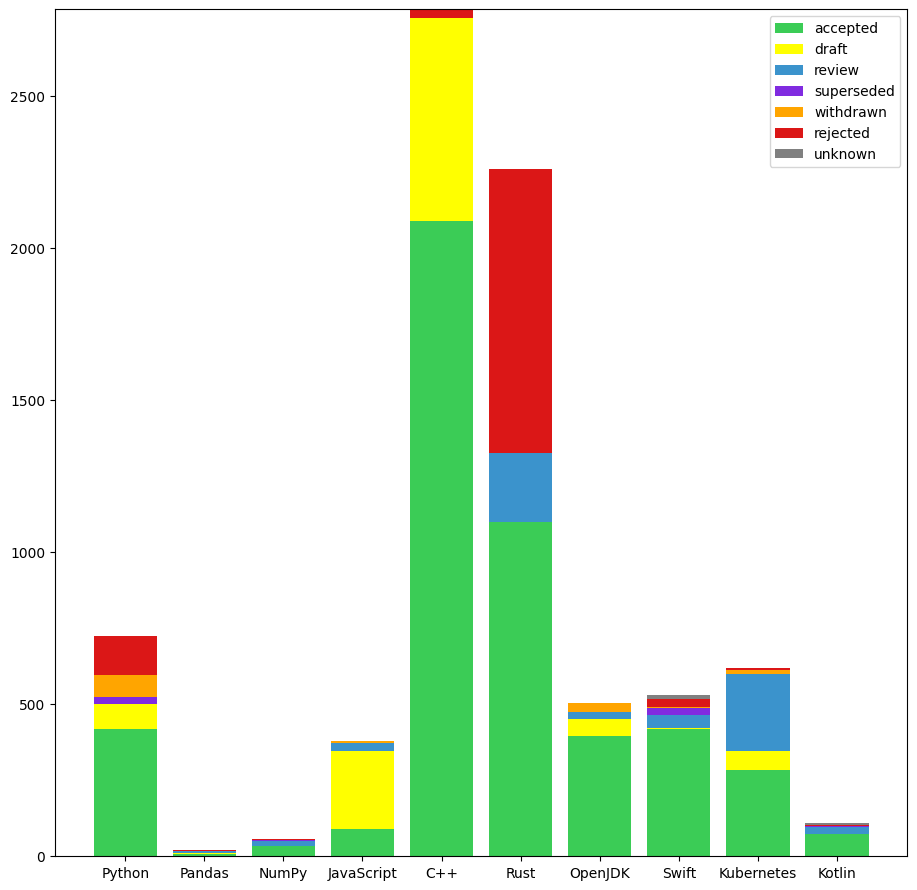

In [9]:
print('Current status proportions:')
plt.figure(figsize=(11,11))
bar_statuses_for_projects(projects.keys())
plt.legend([stat.value for stat in NormalisedStatus])
plt.show()

Status proportions (better view of small ones):


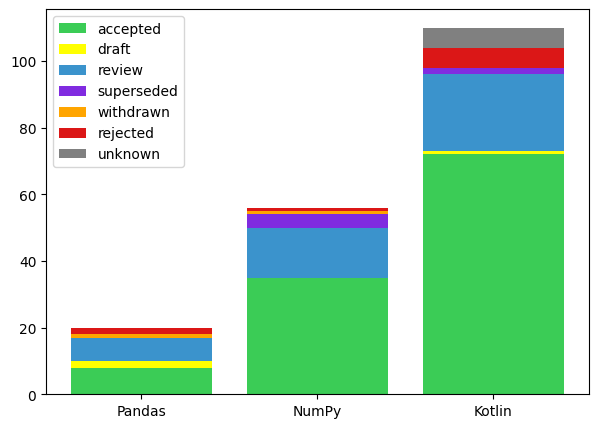

In [114]:
print('Status proportions (better view of small ones):')
plt.figure(figsize=(7,5))
bar_statuses_for_projects([p_id for p_id in projects if p_id in [1,2,9]])
plt.legend([stat.value for stat in NormalisedStatus])
plt.show()

Picking the most popular proposals in each project, for me to manually read through and discover topics:

In [10]:
from sqlalchemy import func, text

num_to_take = 5

print('By number of comments:')
for proj_id, project in projects.items():
  # raw query because orm is painfully slow
  most_comments = session.execute(text(f'''select p.proposal_id from Proposal p join Comment c
    on p.project_id == c.project_id and p.proposal_id == c.proposal_id
    where p.project_id == :pid
    group by p.proposal_id
    order by count(c.comment_id) desc, p.proposal_id desc
    limit :lim'''), params={'pid': proj_id, 'lim': num_to_take})
  # most_comments = session.scalars(select(Proposal.proposal_id)
  #   .join(Comment, onclause=Proposal.project_id.is_(Comment.project_id) & Proposal.proposal_id.is_(Comment.proposal_id))
  #   .where(Proposal.project_id.is_(project.project_id))
  #   .group_by(Proposal.proposal_id)
  #   .order_by(func.count(Comment.comment_id).desc())
  #   .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {[c[0] for c in most_comments]}')

print('By number of revisions:')
for proj_id, project in projects.items():
  most_comments = session.scalars(select(Proposal.proposal_id)
    .join(ProposalRevision)
    .where(Proposal.project_id.is_(proj_id))
    .group_by(Proposal.proposal_id)
    .order_by(func.count(ProposalRevision.revision_index).desc())
    .order_by(Proposal.proposal_id.desc())
    .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {list(most_comments)}')

By number of comments:
PEP: ['8', '572', '517', '318', '426']
PDEP: []
NEP: ['14', '18', '20', '17', '41']
tc39: ['ShadowRealm', 'Updates to Tail Calls to include an explicit syntactic opt-in', 'Record & Tuple', 'Import Attributes', 'Temporal']
ISO C++: []
RFC: ['3946', '3892', '3855', '3834', '3830']
JEP: ['331', '472', '450', '8380294', '522']
Evolution: ['SE-0279', 'SE-0453', 'SE-0258', 'SE-0483', 'SE-0354']
KEP: ['4381', '3063', '4671', '3488', '127']
KEEP: ['0367', '0259', '0427', '0441', '0075']
By number of revisions:
PEP: ['11', '101', '1', '596', '619']
PDEP: ['1-1', '6-1', '10-1', '14-1', '12-1']
NEP: ['50', '35', '29', '18', '0']
tc39: ['Array.fromAsync', 'BigInt Math', 'Call-this operator', 'Bind-this operator', 'Pattern Matching']
ISO C++: ['P0447', 'P0876', 'P1018', 'P0260', 'P1928']
RFC: ['3878', '3537', '2682', '2456', '2299']
JEP: ['8377081', '401', '358', '430', '455']
Evolution: ['SE-0006', 'SE-0492', 'XX-0069', 'SE-0376', 'XX-0023']
KEP: ['1287', '3488', '4603', '10

Below are the manually identified topics from the proposals above:

In [11]:
sep_topics = {
  0: {
    '8': ['code style', 'recommendation'],
    '572': ['syntax'],
    '318': ['syntax', 'api structure'],
    '426': ['integration'],
    '11': ['internal', 'compatibility'],
    '101': ['recommendation'],
    '1': ['meta'],
    '596': ['versioning', 'plan'],
    '619': ['versioning', 'plan'],
  },
  1: {
    '1-1': ['meta'],
    '6-1': ['types'],
    '10-1': ['internal', 'types', 'dev experience'],
    '14-1': ['types'],
    '12-1': ['types', 'api structure'],
  },
  2: {
    '14': ['deprecation'],
    '18': ['internal'],
    '20': ['syntax'],
    '17': ['api structure'],
    '41': ['types', 'syntax'],
    '50': ['types', 'dev experience'],
    '35': ['api structure', 'internal'],
    '29': ['versioning'],
    '0': ['meta'],
  },
  3: {
    'ShadowRealm': ['api structure'],
    'Updates to Tail Calls to include an explicit syntactic opt-in': ['syntax'],
    'Record & Tuple': ['syntax', 'types'],
    'Import Attributes': ['syntax'],
    'Temporal': ['api structure'],
    'Array.fromAsync': ['api structure'],
    'BigInt Math': ['api structure'],
    'Call-this operator': ['syntax'],
    'Bind-this operator': ['syntax'],
    'Pattern Matching': ['syntax'],
  },
  5: {
    '0078': ['dev experience'],
    '0148': ['syntax'],
    '0219': ['api structure', 'concurrency'],
    '0235': ['api structure'],
    '0439': ['api structure'],
    '3537': ['versioning', 'integration'],
  },
  6: {
    '331': ['performance', 'api structure'],
    '472': ['dev experience'],
    '450': ['performance', 'memory'],
    '537': ['api structure'],
    # '223': ['versioning', 'dev experience', 'api structure'],
    '8380294': ['api structure', 'internal', 'performance'],
    '533': ['concurrency', 'api structure'],
    '506': ['api structure', 'performance'],
    '454': ['memory', 'api structure'],
    '352': ['syntax'],
  },
  7: {
    'SE-0279': ['syntax'],
    'SE-0453': ['types', 'api structure'],
    'SE-0258': ['syntax'],
    'SE-0483': ['types', 'syntax'],
    'SE-0354': ['syntax'],
    'SE-0492': ['syntax'],
  },
  9: {
    '0367': ['syntax'],
    '0259': ['syntax'],
    '0427': ['syntax', 'types'],
    '0441': ['syntax', 'types'],
    '0075': ['syntax'],
    '0455': ['syntax'],
    '0452': ['internal', 'syntax'],
    '0430': ['syntax'],
    '0104': ['syntax', 'internal'],
  },
}

In [12]:
"""
Gets the title and the content from the latest revision of a proposal
None if a proposal has no revisions
"""
def proposal_latest_title_content(project_id: int, proposal_id: str) -> tuple[str, str] | None:
  prop = session.scalar(select(ProposalRevision)
    .where(ProposalRevision.project_id.is_(project_id))
    .where(ProposalRevision.proposal_id.is_(proposal_id))
    .order_by(ProposalRevision.created_at.desc())
    .limit(1))
  if not prop: return None
  return prop.title, prop.content

In [13]:
import re

def sanitize_markdown(content: str) -> str:
  return re.sub(r'<!--(?:(?!-->)[\s\S])+-->', '', # remove comments
    re.sub(r'```(?:(?!```)[\s\S])+```', '', # remove code blocks
    re.sub(r'\n\|[^\n]*', '', content))) # remove tables (lines starting with |)

def sanitize_pep(content: str) -> str:
  return re.sub(r'\n[^A-Za-z0-9\n]+\n', '\n', # remove lines with no alphanumeric characters
    re.sub(r'References\n[\s\S]*$|Copyright\n[\s\S]*$', '', content)) # remove everything starting from references or copyright section (usually nothing important)

def sanitize_pdep(content: str) -> str: # these are markdown
  return sanitize_markdown(content)

def sanitize_nep(content: str) -> str: # similar to pep
  return sanitize_pep(content)

def sanitize_rust(content: str) -> str:
  return re.sub(r'^[\s\S]*# Summary', '', # remove all before summary (metadata)
    sanitize_markdown(content))

def sanitize_jep(content: str) -> str:
  return re.sub(r'<code>(?:(?!</code>)[\s\S])+</code>', '', content) # remove code blocks

def sanitize_swift(content: str) -> str:
  return re.sub(r'^[\s\S]*# Introduction|^[\s\S]*# Summary', '', # remove all before introduction/summary (metadata)
    sanitize_markdown(content))

def sanitize_keep(content: str) -> str:
  return sanitize_markdown(content)

content_sanitizer = {
  0: sanitize_pep,
  1: sanitize_pdep,
  2: sanitize_nep,
  5: sanitize_rust,
  6: sanitize_jep,
  7: sanitize_swift,
  9: sanitize_keep,
}

"""
Cleans up the content of a proposal
Picks strategy based on which project it comes from
"""
def sanitize_content(project_id: int, content: str) -> str:
  sanitize = content_sanitizer.get(project_id, identity)
  return re.sub(r'[^A-Za-z0-9 .?!,]', ' ', # remove characters except alphanumeric, space and sentence separators
    re.sub(r'https?://\S+', '', # remove URLs
    sanitize(content)))

def sanitize_title_rust(title: str) -> str:
  return re.sub(r'^[Rr][Ff][Cc]:', '', title)

def sanitize_title_jep(title: str) -> str:
  return re.sub(r'^JEP\s+\S*\s*[:-]|^JEP:|^JEP XXX|^Draft\s+JEP:', '', title)

title_sanitizer = {
  5: sanitize_title_rust,
  6: sanitize_title_jep,
}

"""
Cleans up the title of a proposal
Picks strategy based on which project it comes from
"""
def sanitize_title(project_id: int, title: str) -> str:
  sanitize = title_sanitizer.get(project_id, identity)
  return re.sub(r'[^A-Za-z0-9 ]', ' ', # remove non-alphanum chars
    sanitize(title)).strip()

In [53]:
from sentence_transformers import SentenceTransformer

minilm_embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", token=getenv('HF_TOKEN'))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [40]:
from _io import BufferedWriter

"""
Generate dense embedding, per sentence, using SBERT model
Specify save file to cache the result
"""
def generate_embedding(sentences: list[str], embedder: SentenceTransformer, save_file: BufferedWriter | None = None):
  embedding = embedder.encode(sentences, normalize_embeddings=True)
  if save_file is not None: np.save(save_file, embedding)
  return embedding

# Whether or not to cache embedding results
use_numpy_save = False

"""
Get embedding for a given proposal, with given sentences of text
Aggregates sentence embeddings by taking the mean
Can fetch embeddings from cache file
"""
def get_proposal_embedding(project_id: int, proposal_id: str, sentences: list[str], embedder: SentenceTransformer,
    embedder_name: str, strategy: str):
  assert len(sentences) > 0, f'Empty content provided for embedding ({project_id}, {proposal_id}, {strategy})'
  sent_embeds = None
  if use_numpy_save:
    save_dir = f'cache/embeddings/{project_id}'
    makedirs(save_dir, exist_ok=True)
    file_name = f'{save_dir}/{proposal_id}-{embedder_name}-{strategy}.npy'
    try:
      sent_embeds = np.load(open(file_name, 'rb'))
    except:
      sent_embeds = generate_embedding(sentences, embedder, save_file=open(file_name, 'wb'))
  else:
    sent_embeds = generate_embedding(sentences, embedder)
  return np.mean(sent_embeds, axis=0)

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
# from sklearn.decomposition import PCA
from matplotlib.axes._axes import Axes

def plot_clust_performances(embeds: Iterable[Iterable[float]], cluster_counts: list[int], title: str, ax: Axes):
  scores: list[float] = []
  for num_clusters in cluster_counts:
    clusterer = KMeans(n_clusters=num_clusters, random_state=random_seed)
    _ = clusterer.fit(embeds)
    prop_labels = clusterer.labels_
    assert prop_labels is not None, f'Clustering failed - {num_clusters} clusters'
    scores.append(silhouette_score(embeds, prop_labels))
  _ = ax.set_title(title)
  _ = ax.plot(cluster_counts, scores)
  _ = ax.set_ylim(bottom=0)
  _ = ax.set(xlabel='cluster #', ylabel='silhoutette score')

In [52]:
from nltk.tokenize import sent_tokenize

def plot_clust_performance_on_project(project_id: int, embedder: SentenceTransformer, embedder_name: str):
  prop_ids = project_proposals(project_id)
  prop_titles_contents = [proposal_latest_title_content(project_id, prop_id) for prop_id in prop_ids]
  prop_ids_titles_contents = [(prop_ids[i], title_content[0], title_content[1])
    for i, title_content in enumerate(prop_titles_contents) if title_content is not None]
  prop_ids_sentences = [(prop_id, [sanitize_title(project_id, title)], sent_tokenize(sanitize_content(project_id, content)))
    for prop_id, title, content in prop_ids_titles_contents]
  title_embeds = [get_proposal_embedding(project_id, prop_id, title, embedder, embedder_name, 'title')
    for prop_id, title, _ in prop_ids_sentences]
  content_embeds = [get_proposal_embedding(project_id, prop_id, content, embedder, embedder_name, 'content')
    for prop_id, _, content in prop_ids_sentences]
  for i, e in enumerate(content_embeds):
    if np.any(np.isnan(e)): print(prop_ids_titles_contents[i])
  
  cluster_counts = list(range(2, 15))
  fig, (ax1, ax2) = plt.subplots(1, 2)
  fig.set_figwidth(20)
  _ = fig.suptitle(f'Clustering performance for embedding - {projects[project_id].project_name}')
  # plot_clust_performances(title_embeds, cluster_counts,
  #   f'Title-based', ax1)
  # plot_clust_performances(content_embeds, cluster_counts,
  #   f'Content-based', ax2)
  plt.show()

I explore every project except C++, because of how different their paradigm is.

In [18]:
project_ids_to_explore = [proj_id for proj_id in projects if proj_id not in [4]]

In [55]:
# plot_clust_performance_on_project(0, minilm_embedder, 'minilm')

In [ ]:
mpnet_embedder = SentenceTransformer("all-mpnet-base-v2", token=getenv('HF_TOKEN'))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

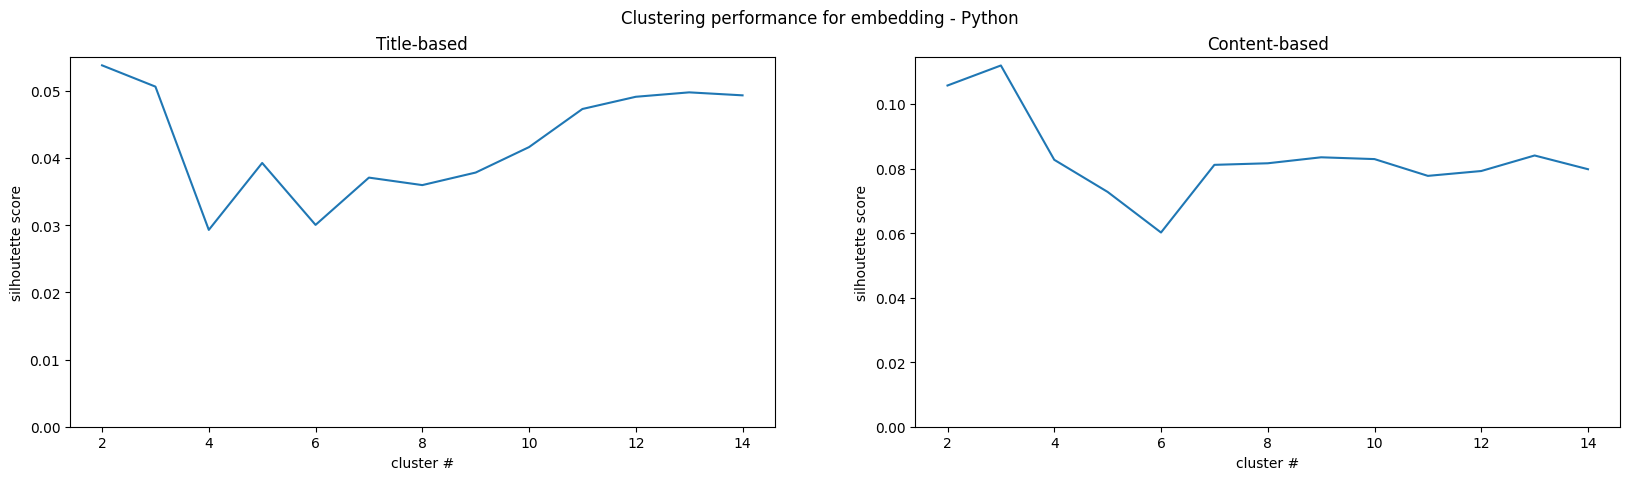

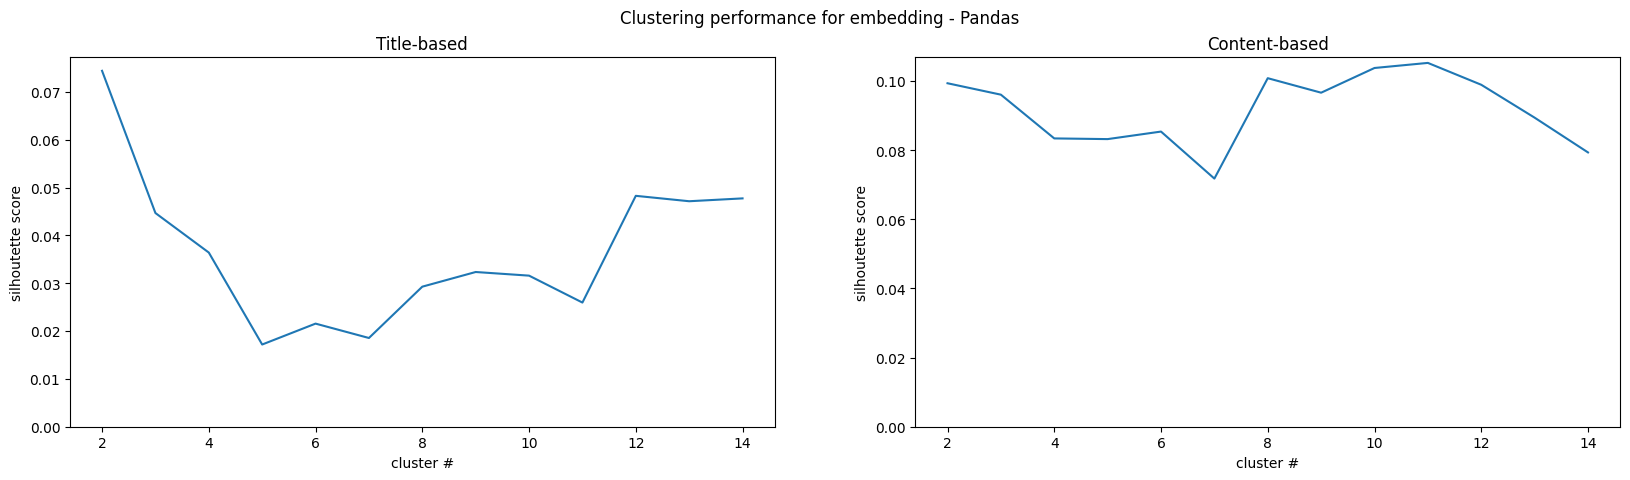

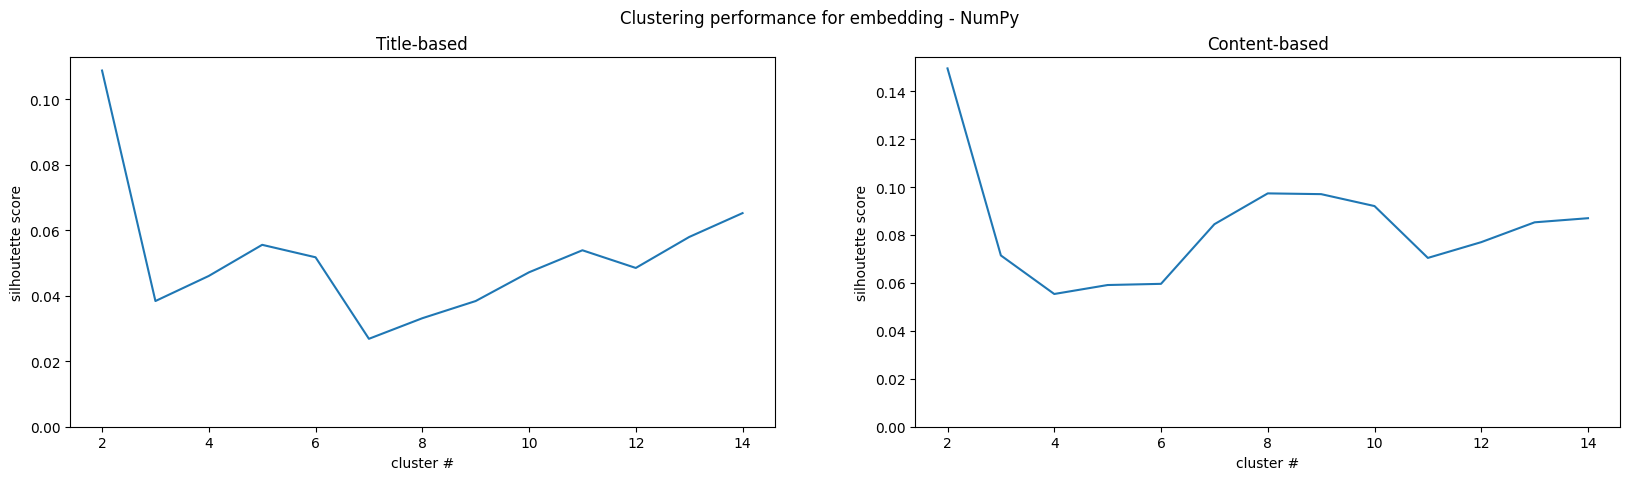

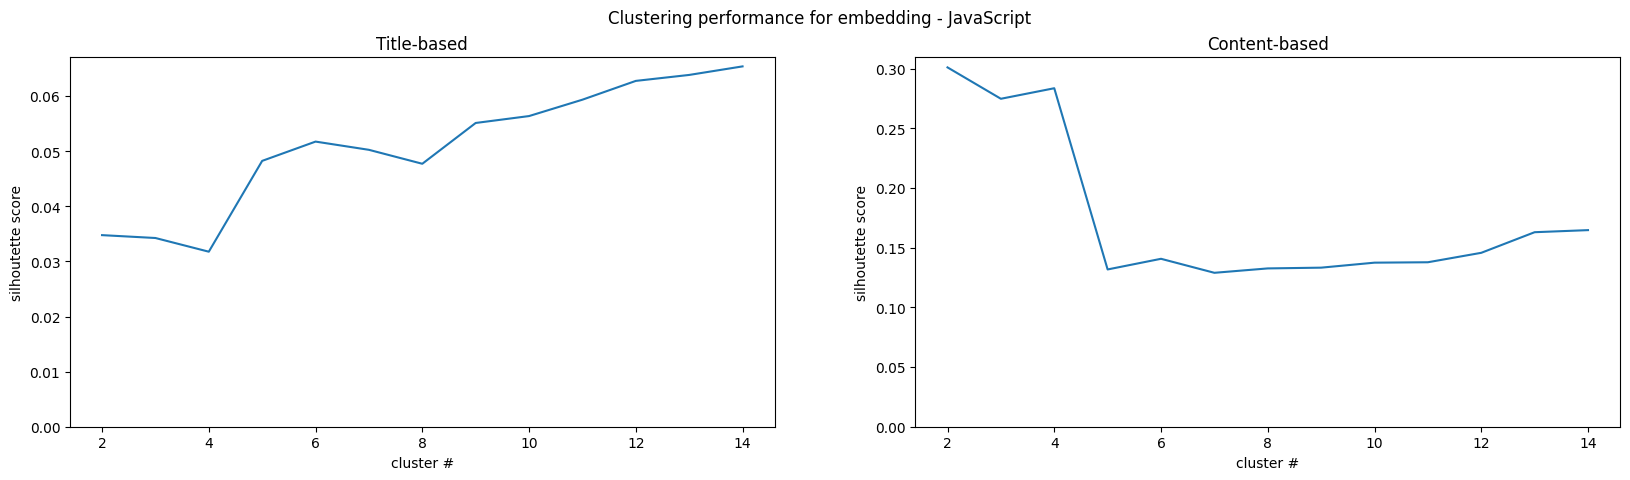

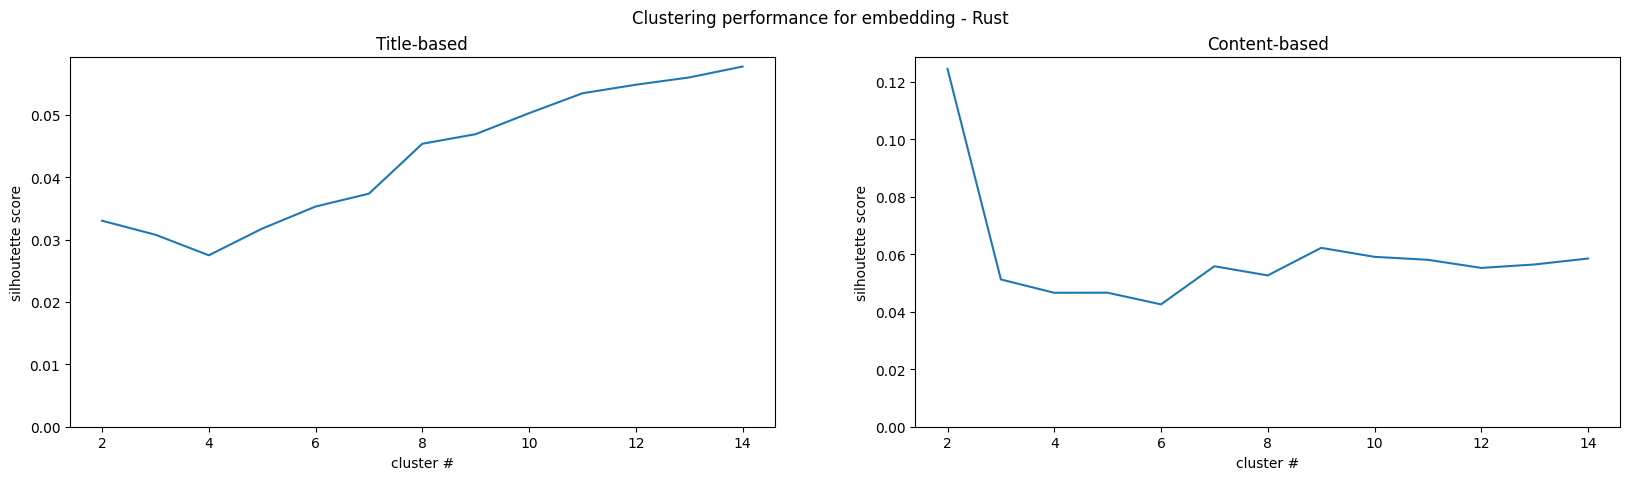

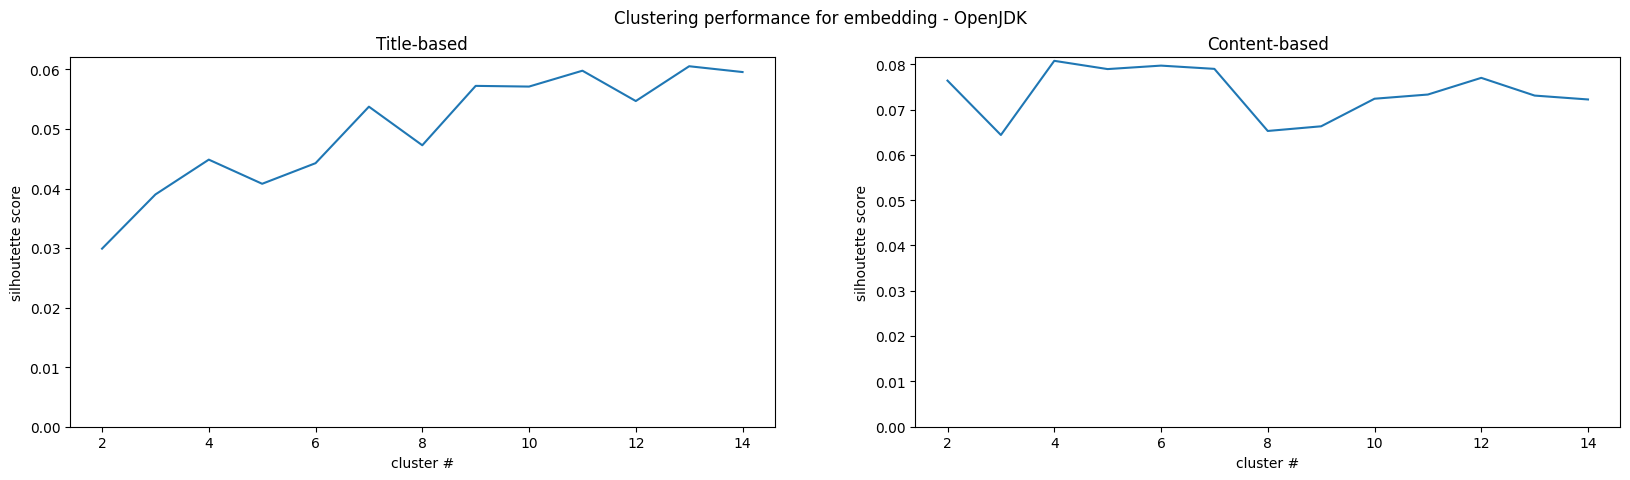

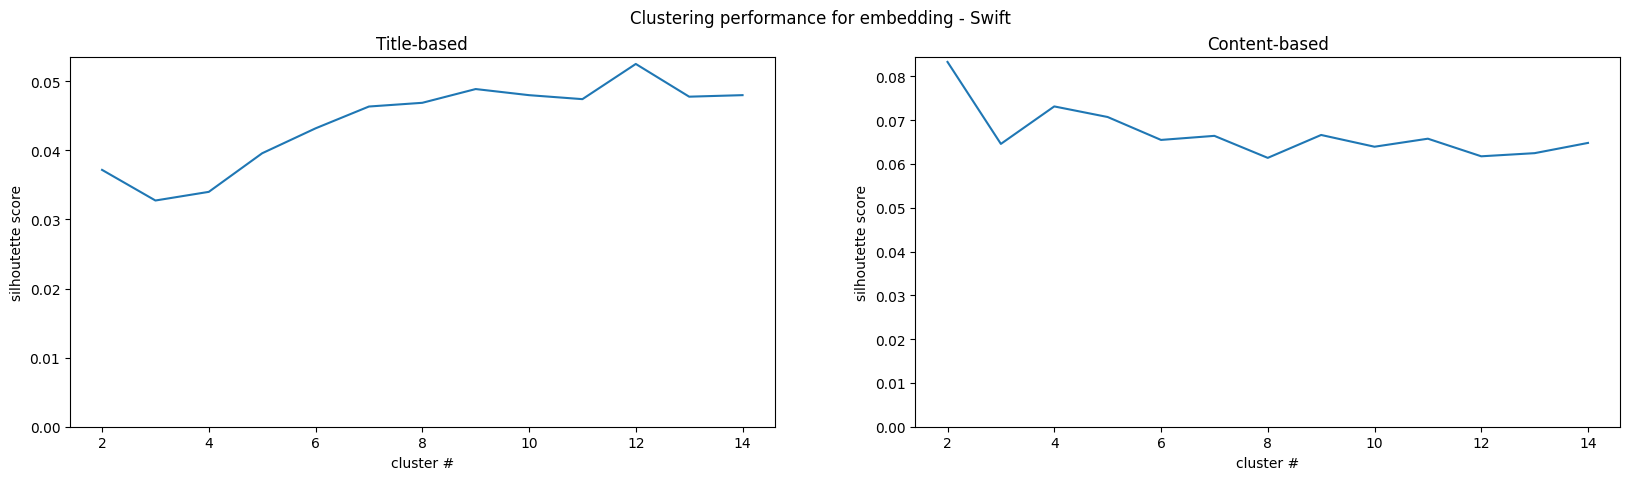

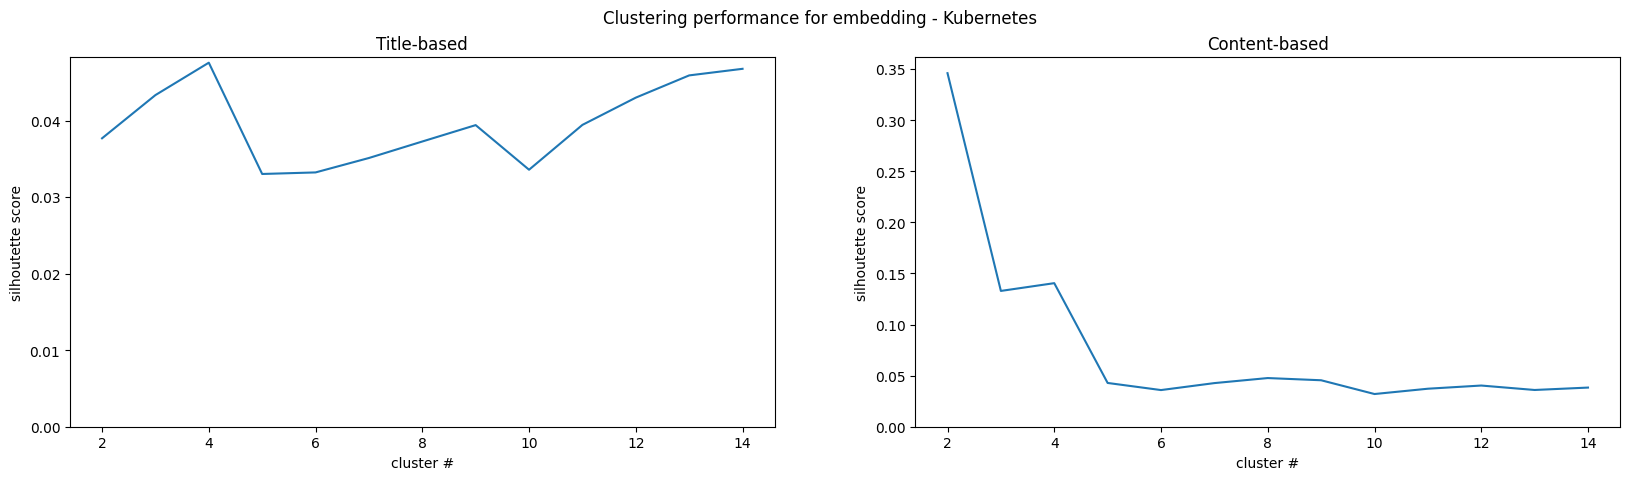

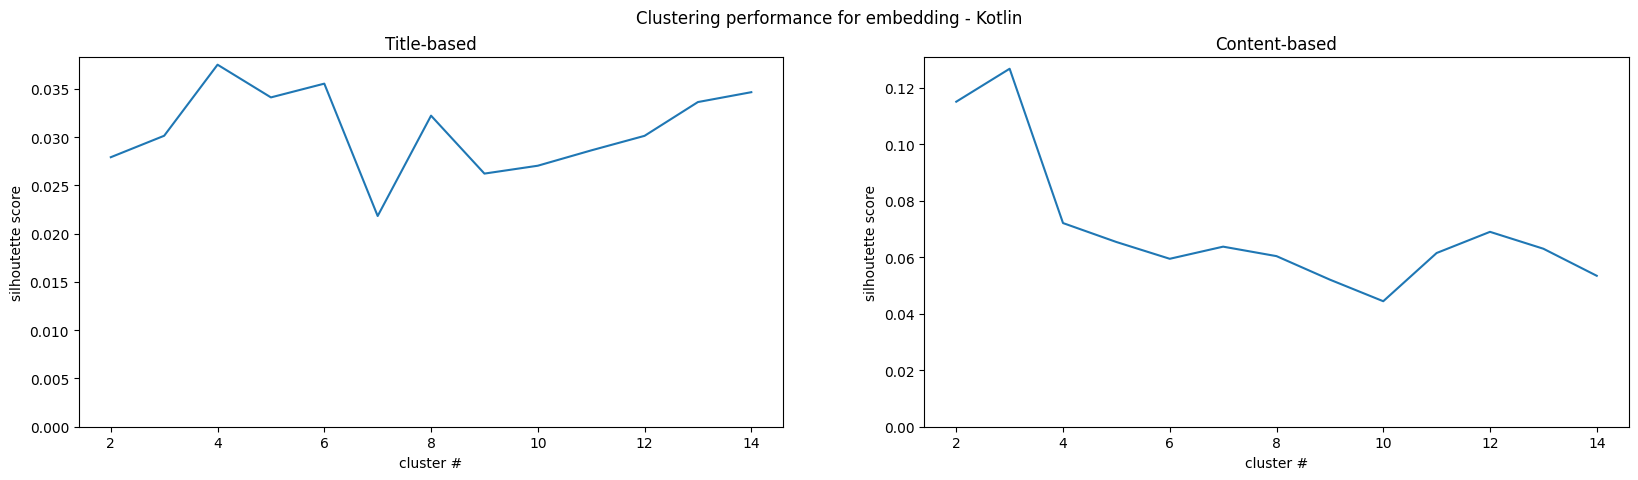

In [ ]:
# plot_clust_performances_all(project_ids_to_explore, mpnet_embedder, 'mpnet')